<a href="https://colab.research.google.com/github/slover1126/slover1126/blob/main/%ED%95%B8%EC%A6%88%EC%98%A8_%EB%A8%B8%EC%8B%A0%EB%9F%AC%EB%8B%9D_9%EC%9E%A5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**9장 비지도 학습**


*   **비지도 학습**은 입력(X)만 있고 레이블(Y)이 없는 문제를 해결하는 방법임
*   다음과 같은 비지도 학습을 본 장에서 다룸
    *   군집(비슷한 샘플을 클러스터로 모음)
    *   이상치 탐지(정상 데이터가 어떻게 보이는지를 학습하고 이상치를 감지)
    *   밀도 추정(데이터셋 생성 확률 과정(random process)의 **확률 밀도 함수(probability density function,PDF)** 를 추정함)


**9.1 군집**



*   **군집** 은 비슷한 샘플끼리 뭉쳐놓은 것으로, 하나의 군집을 **클러스터** 라고 함
*   군집은 고객분류 및 기타 여러 분야에서 사용됨



**9.1.1 $k$-평균**


*   **$k$-평균** 알고리즘은 센트로이드(클러스터의 중심점)를 통해 각 샘플을 클러스터에 할당할 수 있는 방법임(자세한 알고리즘은 뒤에서 서술),K는 클러스터의 수를 의미함
*   **로이드-포지 알고리즘** 이라고도 함

In [1]:
#k-means 코드
from sklearn.cluster import KMeans
import numpy as np
from sklearn.datasets import make_blobs

blob_centers = np.array([
    [ 0.2,  2.3],
    [-1.5,  2.3],
    [-2.8,  1.8],
    [-2.8,  2.8],
    [-2.8,  1.3]
])
blob_std = np.array([0.4, 0.3, 0.1, 0.1, 0.1])
k=5
X, y = make_blobs(n_samples=2000, centers=blob_centers, cluster_std=blob_std, random_state=7)
kmeans  = KMeans(n_clusters=k, random_state=42, n_init = 10)
y_pred = kmeans.fit_predict(X) #X를 바로 예측함

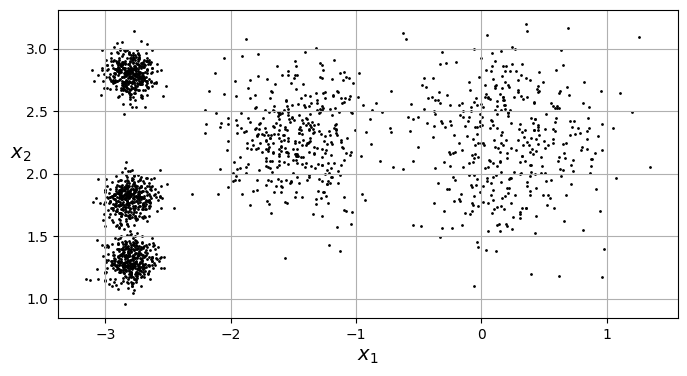

In [2]:
#생성한 데이터 시각화
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.scatter(X[:, 0], X[:, 1], c="black", s=1)
plt.xlabel("$x_1$", fontsize=14)
plt.ylabel("$x_2$", fontsize=14, rotation=0)
plt.grid(True)
plt.show()

In [3]:
#샘플은 5개의 클러스터 중 하나에 할당되며 군집에서 각 샘플의 레이블은 알고리즘이 샘플에 할당한 클래스를 의미함
#KMeans는 변수명.labels_를 통해 예측 레이블 확인 가능

print(y_pred)

print(y_pred is kmeans.labels_)
#True이므로 두 객체가 같음을 확인 가능

[0 0 4 ... 3 1 0]
True


In [4]:
#이 알고리즘이 찾은 센트로이드 5개를 확인
kmeans.cluster_centers_

array([[-2.80214068,  1.55162671],
       [ 0.08703534,  2.58438091],
       [-1.46869323,  2.28214236],
       [-2.79290307,  2.79641063],
       [ 0.31332823,  1.96822352]])

In [5]:
#새로운 샘플에 가장 가까운 센트로이드의 클러스터를 할당하기
X_new = np.array([[0,2], [3,2], [3,3],[-3,2.5]])
kmeans.predict(X_new)
#각각 4번, 4번, 3번, 3번 클러스터로 할당되었음을 의미함

array([4, 4, 4, 3], dtype=int32)

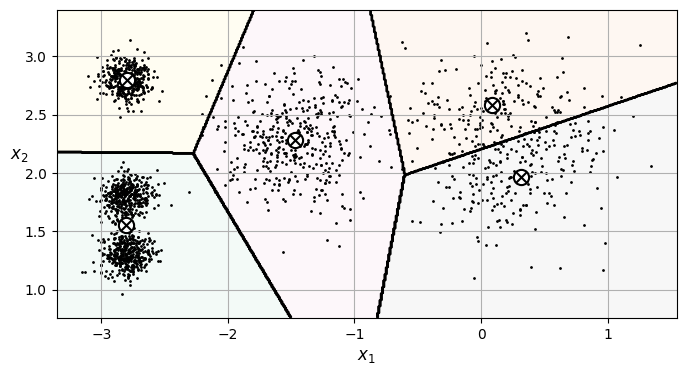

In [6]:
#클러스터의 결정 경계를 보르노이 다이어그램(평면을 특정 점까지의 거리가 가장 가까운 점의 집합으로 분할한 그림)으로 표시하기

# 1. 보로노이 결정 경계 및 센트로이드 시각화 함수
def plot_decision_boundaries(clusterer, X):
    # 그리드 좌표 생성
    x_min, x_max = X[:, 0].min() - 0.2, X[:, 0].max() + 0.2
    y_min, y_max = X[:, 1].min() - 0.2, X[:, 1].max() + 0.2
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500),
                         np.linspace(y_min, y_max, 500))

    # 각 그리드 점의 클러스터 예측
    Z = clusterer.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # 결정 경계선 (보로노이 다이어그램 실선)
    plt.contour(xx, yy, Z, colors='k', linewidths=1.5)
    # 영역 색칠 (선택 사항)
    plt.contourf(xx, yy, Z, alpha=0.15, cmap="Pastel2")

    # 원본 데이터 점
    plt.scatter(X[:, 0], X[:, 1], c='black', s=1)

    # 센트로이드 표시 (흰색 원 + 검은색 X)
    centroids = clusterer.cluster_centers_
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='o', s=120, color='white', edgecolors='black', linewidths=1.5, zorder=10)
    plt.scatter(centroids[:, 0], centroids[:, 1],
                marker='x', s=60, color='black', linewidths=1.5, zorder=11)

    plt.xlabel("$x_1$", fontsize=12)
    plt.ylabel("$x_2$", fontsize=12, rotation=0)

# 2. 출력
plt.figure(figsize=(8, 4))
plot_decision_boundaries(kmeans, X)
plt.grid(True)
plt.show()



*   k-평균은 클러스터의 크기가 많이 다르면 잘 작동하지 않음(클러스터에 할당할 때 센트로이드까지의 거리만을 고려하므로)
*   샘플을 하나의 클러스터에 바로 넣는 **하드 군집(hard clustering)** 보다 샘플에 점수를 부여하는 **소프트 군집(soft clustering)** 이 유용할 수 있으며 이때 점수는 모든 센트로이드까지의 거리나 가우스 방사기저 함수같은 유사도 점수를 사용할 수 있음



In [7]:
# .transform을 통해 각 센트로이드 까지의 거리를 계산한 값을 반환할 수 있음
kmeans.transform(X_new).round(2)
# 첫번째 샘플의 경우 0번 센트로이드와는 2.84, 1번 센트로이드와는 0.59 만큼 떨어져 있다고 해석할 수 있음

array([[2.84, 0.59, 1.5 , 2.9 , 0.31],
       [5.82, 2.97, 4.48, 5.85, 2.69],
       [5.98, 2.94, 4.53, 5.8 , 2.88],
       [0.97, 3.09, 1.55, 0.36, 3.36]])

**K-평균 알고리즘**



1.   레이블이나 센트로이드가 주어지지 않은경우, **랜덤하게 K개의 샘플을 뽑아 그 위치를 센트로이드로 사용**
2.  센트로이드를 통해 각 샘플에 클러스터를 할당함
3.  그 다음 각 클러스터에 속한 좌표들의 평균으로 센트로이드를 이동시킴
4.  다시 레이블 할당(2번 과정 반복)
5.  클러스터 안에 있는 좌표들의 평균으로 센트로이드를 이동시킴(3번 과정 반복)
6.  반복

*   알고리즘이 최소화 하고자 하는 값은 **이너셔(inerita)** 로, k-means의 평가 지표이고, 뒤에서 더 설명함
*   이  알고리즘은 제한된 횟수 안에서 수렴하는 것을 보장함(샘플과 가장 가까운 센트로이드 사이의 평균 제곱 거리는 감소만 하고 음수가 될 수 없으므로)


*   다만 수렴은 보장되지만 운이 없다면 랜덤 초기화 단계에 잘못 설정되면 지역 최솟값으로 수렴할 수 있는 문제가 있음  







**센트로이드 초기화 방법**


*   센트로이드 위치를 근사하게 알 수 있다면 **init 하이퍼파라미터에 센트로이드를 담은 넘파이 배열을 지정하고 n_init = 1 로 설정하면 됨**


In [8]:
#센트로이드를 직접 지정
good_init = np.array([[-3,3], [-3,2],[-3,1],[-1,2],[0,2]])
kmeans = KMeans(n_clusters=5, init=good_init , n_init=1, random_state=42)
kmeans.fit(X)

KMeans(init=array([[-3,  3],
       [-3,  2],
       [-3,  1],
       [-1,  2],
       [ 0,  2]]),
       n_clusters=5, n_init=1, random_state=42)



*   또 다른 방법으로는 알고리즘 자체를 여러번 시행하고, 가장 좋은 센트로이드를 선택하는 방법임
*   **알고리즘의 반복 횟수는 n_init 하이퍼파라미터로 지정함**

*   이때, 최적의 센트로이드를 선택하는 기준이 **각 샘플과 가장 가까운 센트로이드 사이의 제곱 거리 합**인 **이너셔(inertia)** 임 (이너셔가 낮을수록 잘 클러스터링된 것임)
*   KMeans 알고리즘에서 n_init을 지정하면 그 수만큼 반복한 후 이너셔가 가장 낮은 모델을 반환함







In [9]:
#이너셔를 확인하려면 변수명.inertia_ 로 확인하면 됨
kmeans.inertia_

211.59853725816828

In [10]:
# 변수명.scores()는 음숫값을 반환(score()함수는 가장 큰 값을 반환하는 규칙 떄문에 음수를 붙여서 반환시킴)
kmeans.score(X)
#-211.59853725816828 로 음수가 붙어서 나옴

-211.59853725816828

**K-평균++ 알고리즘**


*   적절한 센트로이드를 선택하기 위해 제시된 방법으로, 다른 센트로이드와 거리가 먼 센트로이드를 선택하는 방식을 이용
*   최적이 아닌 솔루션으로 수렴할 가능성을 크게 낮춤



*   알고리즘은 다음과 같이 진행

    1.   첫번째 센트로이드를 샘플에서 무작위로 선택
    2.   다음 센트로이드를 거리의 제곱의 확률에 비례하게 선택
$$P(\mathbf{x}^{(i)}) = \frac{D(\mathbf{x}^{(i)})^2}{\sum_{j=1}^{m} D(\mathbf{x}^{(j)})^2}$$

* $P(\mathbf{x}^{(i)})$ 는 $i$번째 샘플이 센트로이드로 선택될 확률
*   $D(\mathbf{x})$는 가장 가까운 센트로이드 까지의 거리를 의미
* 즉, 센트로이드가 가까이에 있을 경우 센트로이드 주위의 점이 새로운 센트로이드로 선택될 확률을 낮춰줌
    
    3.이러한 방식을 통해 $k$개의 센트로이드를 처음으로 지정함



*   kmeans 클래스는 기본적으로 이 초기화 방법을 사용함




**$k$-평균 속도 개선과 미니배치 $k$-평균**


*   **algorithm = "elkan"** 으로 설정하면 엘칸이 제시한 삼각부등식을 활용하여 셈플과 센트로이드 간의 거리의 상한선과 하한선을 유지하는 방식이 쓸 수 있음
*   불필요한 거리 계산을 줄이는 방식인데, 항상 시간을 줄이는건 아니고 떄로는 훈련속도가 상당히 느려질 수 있음

*   전체 데이터셋을 보지 않고 센트로이드 이동 시 마다 미니배치만을 이용하여 센트로이드를 이동시키는 방법도 사용할 수 있음
*   알고리즘 속도를 3배,4배 정도 향상시킬 수 있고 메모리에 들어가지 않는 대량의 데이터셋을 다루는데 적합함



In [11]:
#사이킷런은 MiniBatchKMeans 라는 클래스에 미니배치 k-평균이 있음
from sklearn.cluster import MiniBatchKMeans

minibatch_kmeans = MiniBatchKMeans(n_clusters=5, random_state=42, n_init=3)
minibatch_kmeans.fit(X)

MiniBatchKMeans(n_clusters=5, n_init=3, random_state=42)



*   메모리에 데이터셋이 들어가지 않는 경우 memmap 클래스를 이용하거나 MiniBatchKMeans의 **partial_fit()** 을 이용하여 한번에 하나의 미니배치를 전달할 수도 있음
*   미니배치 방식이 일반적인 방식보다 속도는 빠르지만 이너셔가 조금 나쁜 단점이 있음



**최적의 클러스터 찾기**


*   클러스터를 임의로 정할 수 없는 경우 여러가지 방법을 통해서 적절한 클러스터를 찾을 수 있음
*   **엘보(elbow) 방식** 과 **실루엣 점수**를 통해 적절한 클러스터를 정할 수 있음



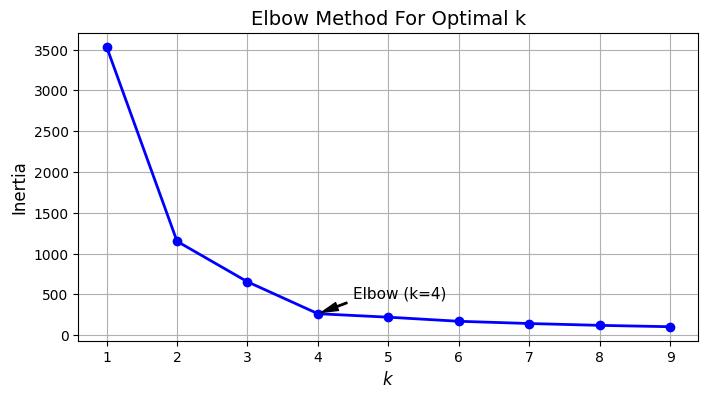

In [12]:
#엘보 그래프
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1. k 값의 범위 설정 (1부터 9까지) 및 이너셔(Inertia) 수집
k_range = range(1, 10)
kmeans_per_k = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X) for k in k_range]
inertias = [model.inertia_ for model in kmeans_per_k]

# 2. 엘보 그래프 시각화
plt.figure(figsize=(8, 4))
plt.plot(k_range, inertias, "bo-", linewidth=2, markersize=6)
plt.xlabel("$k$", fontsize=12)
plt.ylabel("Inertia", fontsize=12)
plt.title("Elbow Method For Optimal k", fontsize=14)
plt.xticks(list(k_range))
plt.grid(True)

# 엘보 지점(기울기가 급격히 꺾이는 k=4 위치) 화살표 표시
plt.annotate(
    "Elbow (k=4)",
    xy=(4, inertias[3]),
    xytext=(4.5, inertias[3] + 200),
    arrowprops=dict(facecolor="black", shrink=0.1, width=1, headwidth=6),
    fontsize=11
)

plt.show()
#클러스터 수에 대해서 이너셔의 감소가 완만해지는 구간을 엘보로 정의하고 이때의 k값을 이용하는 방식
#본 그래프에선 k=4가 적절해보임

**실루엣 계수**


*   엘보 방식은 클러스터 선택이 애매하다는 단점이 있음(어디를 엘보로 놓을지 주관이 들어감)
*   따라서 **실루엣 점수(silhouette score)** 는 모든 샘플에 대한 **실루엣 계수(silhouette coefficient)** 의 평균임  


*   개별 샘플의 실루엣 계수는 다음과 같이 계산됨
$$s(i) = \frac{b(i) - a(i)}{\max\big(a(i), b(i)\big)}$$
*   $s(i)$는 계산된 실루엣 점수
*   $a(i)$는 샘플 $i$와 같은 클러스터에 속한 다른 모든 샘플들 사이의 평균 거리
*   $b(i)$는 샘플 $i$가 속하지 않은 다른 클러스터 각각에 속한 모든 샘플들과의 거리의 평균을 계산했을 때, 그중 가장 작은 거리 평균값(계산된 가장 작은값)

*   실루엣 계수가 1에 가까우면 자기 클러스터에 잘 들어와 있다는 의미
*   실루엣 계수가 0에 가까우면 클러스터의 경계에 있다는 의미
*   실루엣 계수가 -1에 가까우면 잘못된 클러스터에 들어와 있다는 의미



In [13]:
#실루엣 점수를 계산하려면 shilhouette()_score 함수를 사용하면 됨
from sklearn.metrics import silhouette_score
silhouette_score(X, kmeans.labels_)

np.float64(0.655517642572828)

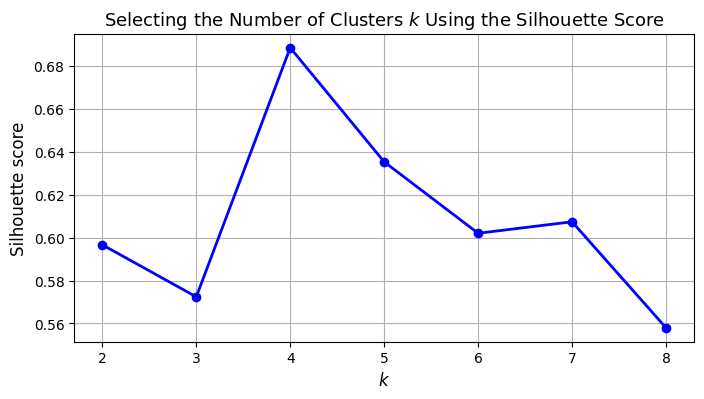

In [14]:
#k를 다르게 했을 때 실루엣 계수의 차이를 통해 적절한 클러스터의 개수를 선택할 수 있음
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. k=2부터 k=8까지 모델 훈련 및 실루엣 점수 계산
k_range = range(2, 9)
kmeans_per_k = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X) for k in k_range]
silhouette_scores = [silhouette_score(X, model.labels_) for model in kmeans_per_k]

# 2. 실루엣 점수 그래프 시각화 (Figure 9-9)
plt.figure(figsize=(8, 4))
plt.plot(k_range, silhouette_scores, "bo-", linewidth=2, markersize=6)
plt.xlabel("$k$", fontsize=12)
plt.ylabel("Silhouette score", fontsize=12)
plt.title("Selecting the Number of Clusters $k$ Using the Silhouette Score", fontsize=13)
plt.grid(True)
plt.show()

#K=4,5 정도로 설정하면 좋을 것이라 해석 가능
#이는 이너셔 만의 비교로는 측정하기 어려움

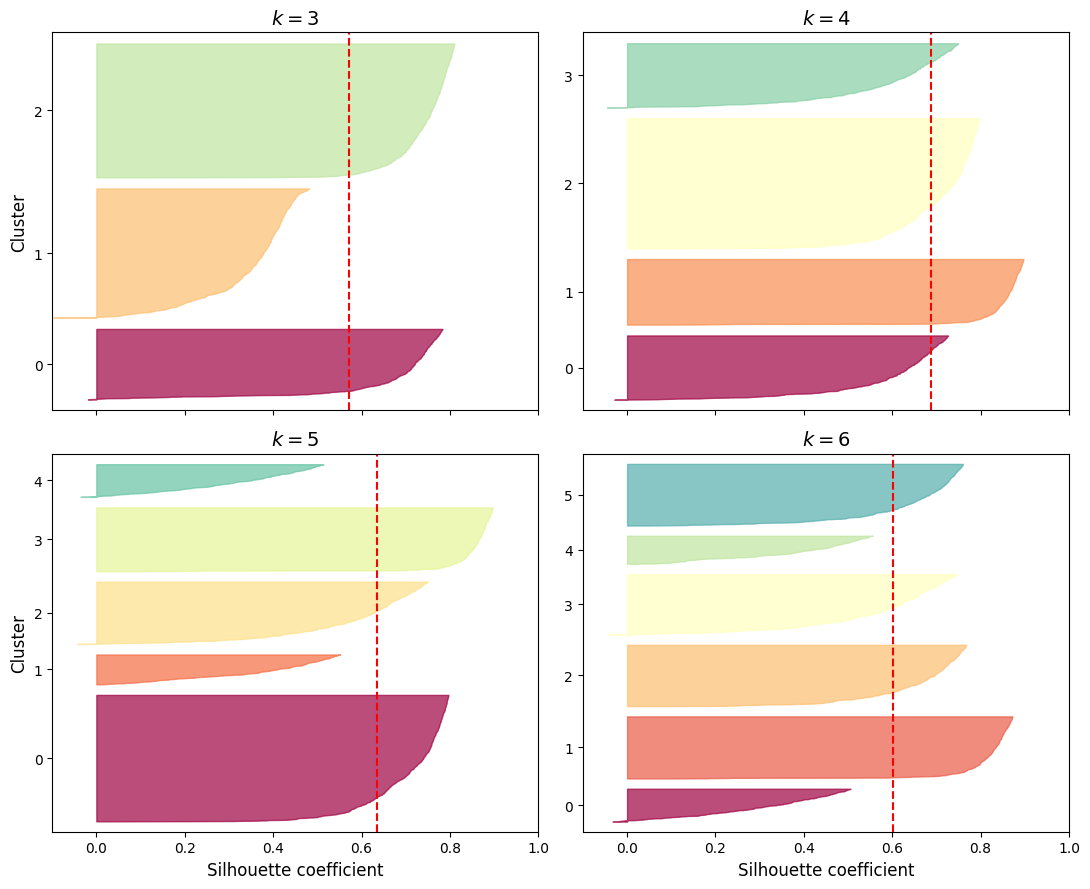

In [15]:
#실루엣 다이어그램(silhouette diagram)으로도 해석 가능
#클러스터 수(k)별 실루엣 계수를 할당된 클러스터와 계수 값으로 정렬하여 표현한 것
#많은 샘플이 파선의 왼쪽에서 멈추면 안좋은 클러스터 수임(다른 클러스터랑 너무 가깝다는 것을 의미하므로)

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.ticker import FixedLocator, FixedFormatter
from sklearn.metrics import silhouette_samples

# k=3, 4, 5, 6 다이어그램 시각화 (Figure 9-10)
plt.figure(figsize=(11, 9))

for idx, k in enumerate((3, 4, 5, 6)):
    plt.subplot(2, 2, idx + 1)

    model = kmeans_per_k[k - 2]
    y_pred = model.labels_
    silhouette_coefficients = silhouette_samples(X, y_pred)

    padding = len(X) // 30
    pos = padding
    ticks = []

    for i in range(k):
        # i번 클러스터의 실루엣 계수 정렬
        coeffs = silhouette_coefficients[y_pred == i]
        coeffs.sort()

        # 칼날 영역 채우기
        color = cm.Spectral(float(i) / k)
        plt.fill_betweenx(np.arange(pos, pos + len(coeffs)), 0, coeffs,
                          facecolor=color, edgecolor=color, alpha=0.7)
        ticks.append(pos + len(coeffs) // 2)
        pos += len(coeffs) + padding

    # 눈금 및 축 영문 레이블 설정
    plt.gca().yaxis.set_major_locator(FixedLocator(ticks))
    plt.gca().yaxis.set_major_formatter(FixedFormatter(range(k)))

    if idx in (0, 2):
        plt.ylabel("Cluster", fontsize=12)
    if idx in (2, 3):
        plt.xlabel("Silhouette coefficient", fontsize=12)
    else:
        plt.tick_params(labelbottom=False)

    # 전체 평균 실루엣 점수 기준 수직 파선
    mean_score = silhouette_scores[k - 2]
    plt.axvline(x=mean_score, color="red", linestyle="--")
    plt.title(f"$k={k}$", fontsize=14)
    plt.axis([-0.1, 1.0, 0, len(X) + (k + 1) * padding])

plt.tight_layout()
plt.show()

**9.1.2 $k$-평균의 한계**

*   $k$-평균은 속도가 빠르고 확장이 용이한 대신 몇가지 단점이 있음
*   센트로이드 지정의 랜덤성으로 인해 최적의 솔루션을 찾기 위해 여러번 실험해야 함
*   클러스터의 크기 또는 밀집도가 서로 다르거나 원형이 아닌경우 잘 작동하지 않음



**9.1.3 군집을 활용한 이미지 분할**


*   **이미지 분할(image segmentaion)** 은 이미지를 여러가지 **세그먼트(segment)** 로 분할하는 작업임
*   여기에는 여러가지 변형이 존재함


    1.   색상 분할
            *   동일한 색상을 가진 픽셀을 같은 세그먼트에 할당함
            *  인공위성 사진을 분석하여 한 지역의 산림 면적이 얼마나 되는지 측정할 때

    2.   시멘틱 분할
            *   동일한 종류의 물체에 속한 모든 픽셀을 같은 세그먼트에 할당함
            *   컴퓨터 비전에서 보행자 이미지를 구성하는 모든 픽셀을 '보행자' 세그먼트에 할당함
    3.   인스턴스 분할
            *   개별 객체에 속한 모든 픽셀을 같은 세그먼트에 할당함
            *   2번에서 개별 보행자를 다른 세그먼트라고 가정함




*   디테일한건 딥러닝으로 하고 여기서는 간단한 이미지로 분할작업 진행함






In [16]:
#교재 예시 이미지 가져오기
import urllib.request
import PIL.Image

# 1. 핸즈온 머신러닝 3판 공식 GitHub에서 ladybug.png 다운로드
url = "https://github.com/ageron/handson-ml3/raw/main/images/unsupervised_learning/ladybug.png"
filepath = "ladybug.png"
urllib.request.urlretrieve(url, filepath)

# 2. 교재 코드 그대로 넘파이 배열로 로드
image = np.asarray(PIL.Image.open(filepath))
print(image.shape)  # (533, 800, 3) 출력

(533, 800, 3)




*   이 이미지는 3D 배열로 표시되며 각각 높이, 너비, 색상 채널의 수를 의미(이 경우 3->RGB임)



In [17]:
#배열의 크기를 바꾸어 RGB 색상 리스트로 바꾸어 K-means를 적용하기

X = image.reshape(-1, 3)
kmeans = KMeans(n_clusters=8, random_state=42, n_init=10).fit(X)
segmented_img = kmeans.cluster_centers_[kmeans.labels_]
segmented_img = segmented_img.reshape(image.shape)

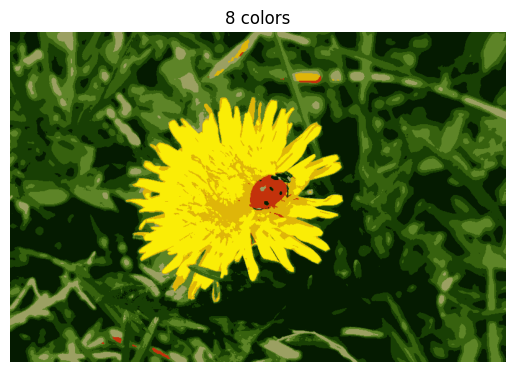

In [18]:
#시각화(교재 이미지와 비교하기)
import matplotlib.pyplot as plt

plt.imshow(segmented_img.astype(np.uint8))
plt.title("8 colors")
plt.axis("off")
plt.show()

#좀 뭉게지긴 했어도 형체를 알아볼 수 있을 정도의 이미지 분할이 이루어짐

**9.1.4 군집을 사용한 준지도 학습**



*   군집을 사용하는 또 다른 사례는 준지도 학습임
*   가진 데이터의 일부만 레이블이 있고, 레이블이 있는 데이터는 적을 때 이용할 수 있음



In [19]:
#MNIST 숫자 데이터셋을 활용

from sklearn.datasets import load_digits

#X_digits는 이미지가 배열화된 값, y_digits는 정답 레이블임
X_digits, y_digits = load_digits(return_X_y=True)

#print(X_digits)
#print(y_digits)

#train, test 분리
X_train, y_train = X_digits[:1400], y_digits[:1400]
X_test, y_test =  X_digits[1400:], y_digits[1400:]

In [20]:
#50개의 샘플에 대한 레이블만 있다고 가정
#이 50개의 샘플에 대해 로지스틱 회귀 모델 훈련

from sklearn.linear_model import LogisticRegression

n_labeled = 50
log_reg = LogisticRegression(max_iter=10_000)
log_reg.fit(X_train[:n_labeled], y_train[:n_labeled])

LogisticRegression(max_iter=10000)

In [21]:
#테스트 세트의 점수 확인
log_reg.score(X_train, y_train)

0.8021428571428572

In [22]:
#훈련 세트를 50개의 클러스터로 모아 센트로이드에서 가장 가까운 이미지를 찾기

k=50
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
X_digits_dist = kmeans.fit_transform(X_train) #fit_transform으로 X_train을 센트로이드까지의 거리로 바꾸기
representative_digit_idx = np.argmin(X_digits_dist, axis=0) #열 단위로 클러스터와의 거리가 최소가 되는 값의 인덱스를 반환
X_representative_digits = X_train[representative_digit_idx] #그 인덱스를 대표 이미지(클러스터와 거리가 최소가 되는 이미지)를 반환

In [23]:
#일일이 눈으로 보고 적는 대신 y_train에서 동일 인덱스로 정답 바로 추출
y_representative_digits = y_train[representative_digit_idx]
#일일이 보고 해도 안되는 이슈가 있어 그냥 레이블 있는거 사용

In [24]:
#대표 이미지를 활용해서 로지스틱 회귀 학습
log_reg = LogisticRegression(max_iter=10_000)
log_reg.fit(X_representative_digits, y_representative_digits)
log_reg.score(X_test, y_test)
#83%로 성능이 향상됨을 보임

0.8387909319899244

In [25]:
#이렇게 정해진 대표 이미지의 레이블을 다른 모든 레이블에 붙여넣을 수 있음
#이를 "레이블 전파(label propagation)" 이라고 함

y_train_propagated = np.empty(len(X_train), dtype=np.int64)
for i in range(k):
    y_train_propagated[kmeans.labels_ == i ] = y_representative_digits[i]

In [26]:
#다시 훈련하고 성능 확인하기
log_reg = LogisticRegression()
log_reg.fit(X_train, y_train_propagated)
log_reg.score(X_test, y_test)
#좀 더 향상되었음을 확인할 수 있음

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


0.8589420654911839

In [27]:
#클러스터 중심에서 가장 먼 1%의 샘플을 제거한 후 성능 확인
#가장 먼 1%의 샘플의 거리를 -1로 설정후 그 데이터셋을 제외한 데이터셋을 생성

percentile_closest = 99

X_cluster_dist = X_digits_dist[np.arange(len(X_train)), kmeans.labels_]
for i in range(k):
    in_cluster = (kmeans.labels_ == i)
    cluster_dist = X_cluster_dist[in_cluster]
    cutoff_distance = np.percentile(cluster_dist, percentile_closest)
    above_cutoff = (X_cluster_dist > cutoff_distance)
    X_cluster_dist[in_cluster & above_cutoff] = -1

partially_propagated = (X_cluster_dist != -1)
X_train_partially_propagated = X_train[partially_propagated]
y_train_partially_propagated = y_train_propagated[partially_propagated]

In [28]:
#부분적으로 전파한(1%를 잘라낸) 데이터셋으로 다시 훈려시키기
log_reg = LogisticRegression(max_iter =10_000)
log_reg.fit(X_train_partially_propagated,y_train_partially_propagated)
log_reg.score(X_test, y_test)
#교재는 score가 올랐는데 이게 무슨 일일까...

0.8564231738035264

In [29]:
#전파된 레이블의 정확도
(y_train_partially_propagated == y_train[partially_propagated]).mean()
#정확도가 약 95%정도임

np.float64(0.9548148148148148)



*   사이킷런 내부에서 **sklearn.semi_supervised** 패키지 안에 있는 **LabelSpreading** 과 **LabelPropagation** 을 통해 레이블 전파를 할 수 있음(모든 샘플 간의 유사도 행렬을 만들고 전파를 시행함)
*   같은 패키지의 **SelfTraingClassifier** 는 클래스를 통해 레이블이 지정된 샘플에서 훈련한 후 이를 사용하여 레이블이 지정되지 않은 샘플의 레이블을 예측함
*   그런 다음 가장 확신하는 레이블로 훈련 세트를 다 채울 때까지 이 훈련과 레이블 지정 프로세스를 반복함



**능동 학습**
*   모델과 훈련 세트를 지속적으로 향상시키기 위한 방법으로 **능동 학습(active learning)** 을 반복할 수 있음
*   이 방법은 전문가가 학습 알고리즘과 상호작용하며 알고리즘이 요청할 때 특정 샘플의 레이블을 직접 붙이는 방식임


*   여러 방법이 있지만 가장 널리 사용되는 **불확실성 샘플링(uncertainity sampling)** 이고 다음과 같이 이루어짐


    1.   지금까지 수집한 레이블된 샘플에서 모델을 훈련하고 이 모델을 사용해 레이블되지 않은 모든 샘플에 대한 예측을 만듦
    2.   모델이 가장 불확실하게 예측한 샘플(즉, 추정 확률이 낮은 샘플)을 전문가에게 보내 레이블을 붙임
    3.  레이블을 부여하는 노력만큼의 성능이 향상되지 않을 때까지 이를 반복함

*   다른 능동학습 전략은 **모델을 가장 크게 바꾸는 샘플이나 모델 검증 수를 가장 크게 떨어뜨리는 샘플, 여러개의 모델이 동일한 예측을 내지 않는 샘플에 대해 레이블을 요청하는 것**임






**9.1.5 DBSCAN**


*   **DBSCAN(density-based spatial clustering of applications with noise)** 알고리즘은 밀집된 연속적 지역을 클러스터로 만드는 방법임
*   작동 방식은 다음과 같음


    1.   알고리즘이 각 샘플에서 지정된 거리인 $\epsilon$ 내에 샘플이 몇개 있는지 계산함(이 지역을 샘플의 (**$\epsilon$ - 이웃** (**$\epsilon$ - neighborhood**) 이라고 함)): eps 하이퍼파라미터로 이걸 설정
    2.   자기 자신을 포함해 $\epsilon$ - 이웃 내에 적어도 **min_samples** 개의 샘플이 있다면 이를 **핵심 샘플(core sample)** 로 간주함
    3.  핵심 샘플의 이웃에 있는 모든 샘플은 같은 클러스터로 배정되며 이웃에는 다른 핵심 샘플이 포함될 수 있음. 따라서 핵심샘플의 이웃의 이웃은 계속해서 하나의 클러스터를 형성해 나감
*   이때 핵심 샘플도 아니고 이웃도 아닌 샘플은 이상치로 판정함
*   이 알고리즘은 모든 클러스터들이 밀집되지 않은 지역과 구분될 때 좋은 성능을 냄





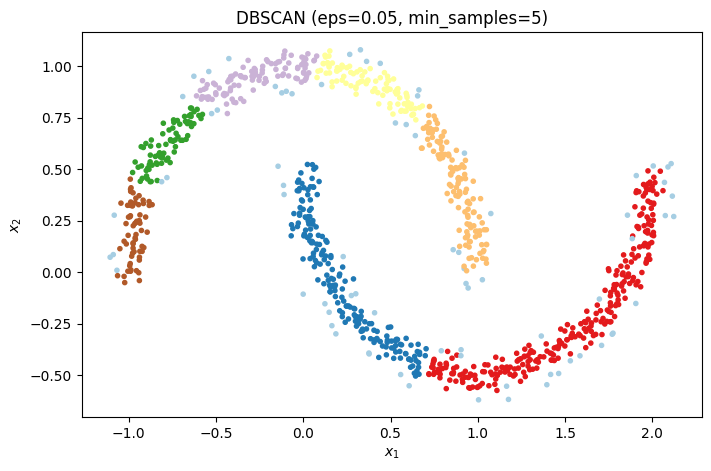

In [38]:
#초승달 데이터셋을 활용하여 DBSCAN 테스트
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt

X, y = make_moons(n_samples=1000, noise=0.05, random_state=42)

# DBSCAN  (eps 반경과 최소 샘플 수 지정)
dbscan = DBSCAN(eps = 0.05, min_samples=5)
dbscan.fit(X) #X만 넣음

#시각화
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=dbscan.labels_, cmap="Paired", marker=".")
plt.title(f"DBSCAN (eps={dbscan.eps}, min_samples={dbscan.min_samples})")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.show()

In [40]:
#샘플의 레이블은 변수명.labels 에 저장되어 있음
dbscan.labels_[:10]
#-1 클러스터는 이상치를 의미함

array([ 0,  2, -1, -1,  1,  0,  0,  0,  2,  5])

In [41]:
#핵심 샘플의 인덱스는 변수명.core_sample_indices_ 에서 확인 가능
len(dbscan.core_sample_indices_)
#개수만 출력

808

In [43]:
#샘플의 인덱스 값을 일부 출력
dbscan.core_sample_indices_[:10]

array([ 0,  4,  5,  6,  7,  8, 10, 11, 12, 13])

In [44]:
#실제 좌표값은 변수명.components에 저장되어 있음
dbscan.components_

array([[-0.02137124,  0.40618608],
       [-0.84192557,  0.53058695],
       [ 0.58930337, -0.32137599],
       ...,
       [ 1.66258462, -0.3079193 ],
       [-0.94355873,  0.3278936 ],
       [ 0.79419406,  0.60777171]], shape=(808, 2))

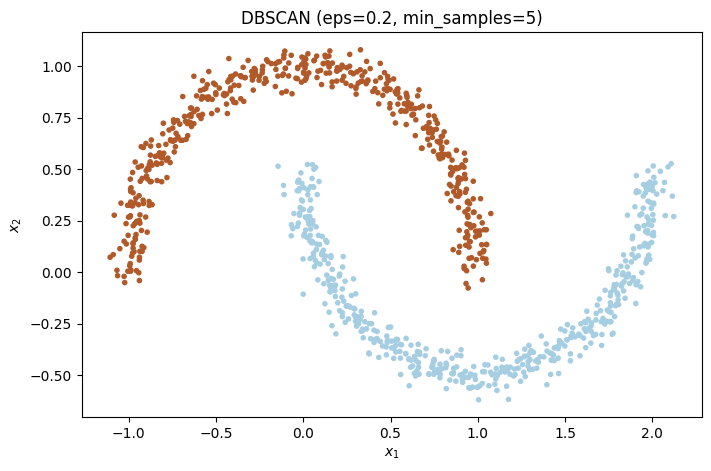

In [45]:
#초승달 데이터셋을 활용하여 DBSCAN 테스트
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons
import matplotlib.pyplot as plt

X, y = make_moons(n_samples=1000, noise=0.05, random_state=42)

# DBSCAN  (eps 반경과 최소 샘플 수 지정)
dbscan = DBSCAN(eps = 0.20, min_samples=5)
dbscan.fit(X) #X만 넣음

#시각화
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], X[:, 1], c=dbscan.labels_, cmap="Paired", marker=".")
plt.title(f"DBSCAN (eps={dbscan.eps}, min_samples={dbscan.min_samples})")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.show()

#eps=0.20으로 설정 시 완벽하게 잘 클러스터링 된걸 확인할 수 있음



*   DBSCAN은 새로운 데이터에 대한 예측을 반환하는 predict()를 제공하지 않고 훈련 데이터의 클러스터 번호를 반환하는 fit_predict() 만을 제공함
*   새로운 샘플이 추가되는 경우 기존의 클러스터가 변하여 결과가 전체적으로 달라질 수 있기 떄문임


*   결국 이 알고리즘은 새로운 샘플에 대해 클러스터를 예측할 수는 없음
*   따라서 사용자가 필요한 예측기를 직접 선택해야 함




In [47]:
#교재에선 예측기로 KNeighborClassifier를 선택함
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=50)
knn.fit(dbscan.components_, dbscan.labels_[dbscan.core_sample_indices_])
#학습용 X에는 코어 샘플을, y에는 그 클러스터를 지정함
#새로운 샘플이 들어오면 50개의 이웃된 샘플을 보고 클러스터를 할당

KNeighborsClassifier(n_neighbors=50)

In [53]:
#새로운 데이터를 넣어서 확인
X_new = np.array([[-0.5,0],[0,0.5],[1,-0.1],[2,1]])
print(knn.predict(X_new))

[1 0 1 0]


In [54]:
#각 클러스터에 속할 확률도 출력 가능
print(knn.predict_proba(X_new))

[[0.18 0.82]
 [1.   0.  ]
 [0.12 0.88]
 [1.   0.  ]]


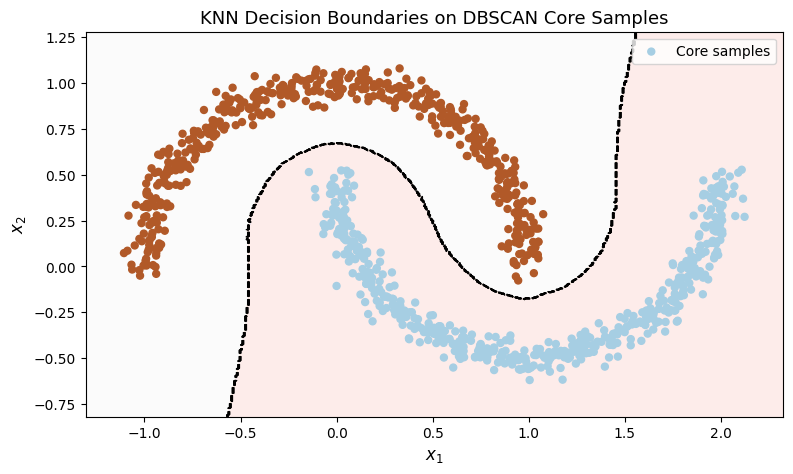

In [55]:
#클러스터와 knn으로 만들어진 결정 경계 시각화
# 1. 격자 생성 및 결정 경계 예측
x0_min, x0_max = X[:, 0].min() - 0.2, X[:, 0].max() + 0.2
x1_min, x1_max = X[:, 1].min() - 0.2, X[:, 1].max() + 0.2
xx, yy = np.meshgrid(np.linspace(x0_min, x0_max, 500), np.linspace(x1_min, x1_max, 500))
Z = knn.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

# 2. 결정 경계 및 데이터 시각화
plt.figure(figsize=(9, 5))
plt.contourf(xx, yy, Z, alpha=0.25, cmap="Pastel1")
plt.contour(xx, yy, Z, colors="k", linewidths=1.2, linestyles="--")

# 핵심 샘플 산점도 (components_ 직접 활용)
plt.scatter(
    dbscan.components_[:, 0], dbscan.components_[:, 1],
    c=dbscan.labels_[dbscan.core_sample_indices_],
    cmap="Paired", marker="o", s=25, label="Core samples"
)

# 이상치 샘플 표시
anomalies_mask = (dbscan.labels_ == -1)
if np.any(anomalies_mask):
    plt.scatter(
        X[anomalies_mask, 0], X[anomalies_mask, 1],
        c="red", marker="x", s=35, label="Anomalies"
    )

plt.xlabel("$x_1$", fontsize=12)
plt.ylabel("$x_2$", fontsize=12)
plt.title("KNN Decision Boundaries on DBSCAN Core Samples", fontsize=13)
plt.axis([x0_min, x0_max, x1_min, x1_max])
plt.legend(loc="upper right")
plt.show()

In [57]:
#핵심 샘플과 거리가 멀면 이상치로 분류(X_new 점들과 가장 가까운 핵심 샘플 하나를 찾아서 그 거리가 0.2보다 멀면 이상치로 판단)
y_dist, y_pred_idx = knn.kneighbors(X_new, n_neighbors=1)
y_pred = dbscan.labels_[dbscan.core_sample_indices_][y_pred_idx]
y_pred[y_dist>0.2] = -1
y_pred.ravel()

array([-1,  0,  1, -1])



*   DBSCAN은 클러스터의 모양과 개수에 상관없이 감지 할 수 있음
*   그리고 이상치에 안정적이고 하이퍼파라미터 수도 적음(**eps와 min_samples** 2개)
*   하지만 클러스터 간의 밀집도가 크게 다르거나 일부 클러스터 주변에 저밀도 영역이 충분히 없는 경우 클러스터 결정에 어려움이 있음
*   계산 복잡도가 대략 $O(m^2 \times n)$이므로 대규모 데이터셋으로 확장하기 어려움
*   다양한 밀도의 클러스터를 DBSCAN보다 더 잘 찾는 **계층적 DBSCAN(HDBSCAN, hierarchical DBCSCAN)** 도 있


**9.1.6 다른 군집 알고리즘**



*   **병합 군집**
*   **BIRCH(balanced iterative reducing and clustering using hierarchies)**
*   **평균 - 이동**
*   **유사도 전파**
*   **스펙트럼 군집**



